# shelfvision demo

Find objects by name with OWLv2 (zero-shot), read the Code128 labels stuck on them with a reader written
from scratch, and estimate the 3D surface normal of each label with MoGe-2. It runs on a CPU, or on an
NVIDIA GPU with `pixi run -e gpu notebook` (see `DEVICE` in the setup); the outputs saved here were
computed on the CPU.

**Run it**

```bash
pixi install
pixi run notebook                       # opens this notebook in JupyterLab
pixi run jupyter nbconvert --to notebook --execute --inplace demo.ipynb   # or run it end to end
```

The photos are seven public-domain desk photos from Wikimedia Commons, with 23 Code128 labels added by
`tools/make_examples.py`; their sources are in `examples/input/SOURCES.md`. The first run downloads the
model weights from Hugging Face (OWLv2 about 590 MB, MoGe-2 about 135 MB, and SAM 2.1 about 150 MB only
with `SEGMENT = True`). On this machine (Ryzen 5 7520U, no GPU, 8 torch threads) all the stages of a new
photo took 124 s on average in the run the README quotes, most of it the barcode reader on these busy
desks (20 to 149 s per photo), and the same queries again about 0.1 s (section 7), because each photo
keeps what it has already computed. Section 9 compares this run with those figures.

## 1. Setup

In [1]:
import warnings

# tqdm warns in notebooks without ipywidgets; it only concerns progress bars, which are turned off below
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import json
import os
from io import BytesIO
from pathlib import Path
from time import perf_counter

from IPython.display import Image as DisplayImage
from IPython.display import display
from PIL import Image
from transformers.utils import logging as transformers_logging

from shelfvision.datatypes import Barcode, DetectedObject
from shelfvision.export import save_report
from shelfvision.images import save_image
from shelfvision.orchestrator import Orchestrator
from shelfvision.timing import record, write_report

transformers_logging.disable_progress_bar()
INPUT = Path("examples") / "input"
OUTPUT = Path("examples") / "output"
# Images are shown reduced and as JPEG, so that the saved notebook stays light
DISPLAY_WIDTH = 960


def show(image: Image.Image, width: int = DISPLAY_WIDTH) -> None:
    small = image.copy()
    small.thumbnail((width, width))
    buffer = BytesIO()
    small.save(buffer, "JPEG", quality=85)
    display(DisplayImage(data=buffer.getvalue()))


def print_objects(objects: tuple[DetectedObject, ...]) -> None:
    for item in objects:
        box = tuple(round(value) for value in (item.box.x0, item.box.y0, item.box.x1, item.box.y1))
        print(f"  {item.name:<12} score {item.score:.2f}  box {box}")


def print_barcodes(barcodes: tuple[Barcode, ...]) -> None:
    for code in barcodes:
        normal = "none" if code.normal is None else "(" + ", ".join(f"{v:+.2f}" for v in code.normal) + ")"
        print(f"  {code.value:<12} center {tuple(round(v) for v in code.center)}  normal {normal}")


# "auto" runs on an NVIDIA GPU when the gpu environment sees one (`pixi run -e gpu notebook`), and
# on the CPU otherwise; "cpu" or "cuda" force one. The results below were computed on the CPU
DEVICE = "auto"
# True adds the outline of each object (SAM 2.1, downloaded on first use) and links codes by it
SEGMENT = False
# One torch thread per logical core; torch would use one per physical core
orchestrator = Orchestrator(threads=os.cpu_count(), device=DEVICE, segment=SEGMENT)
scenes = {path.name: orchestrator.open(path) for path in sorted(INPUT.glob("*.jpg"))}
print("Photos:", ", ".join(scenes))

Photos: input_1.jpg, input_2.jpg, input_3.jpg, input_4.jpg, input_5.jpg, input_6.jpg, input_7.jpg


## 2. Find objects by name

The input is a list of names or `"all"`; the output is the image with the box of each object found, and
the prompt written above it. A list runs OWLv2 with the requested names, and each one must also beat
the closest words of a general vocabulary, so a name that is not in the photo gives no box: there is no
banana on this desk.

Prompt ['laptop', 'book', 'banana']: 2 objects
  laptop       score 0.59  box (1994, 263, 3189, 1470)
  book         score 0.40  box (1968, 1957, 3465, 2269)


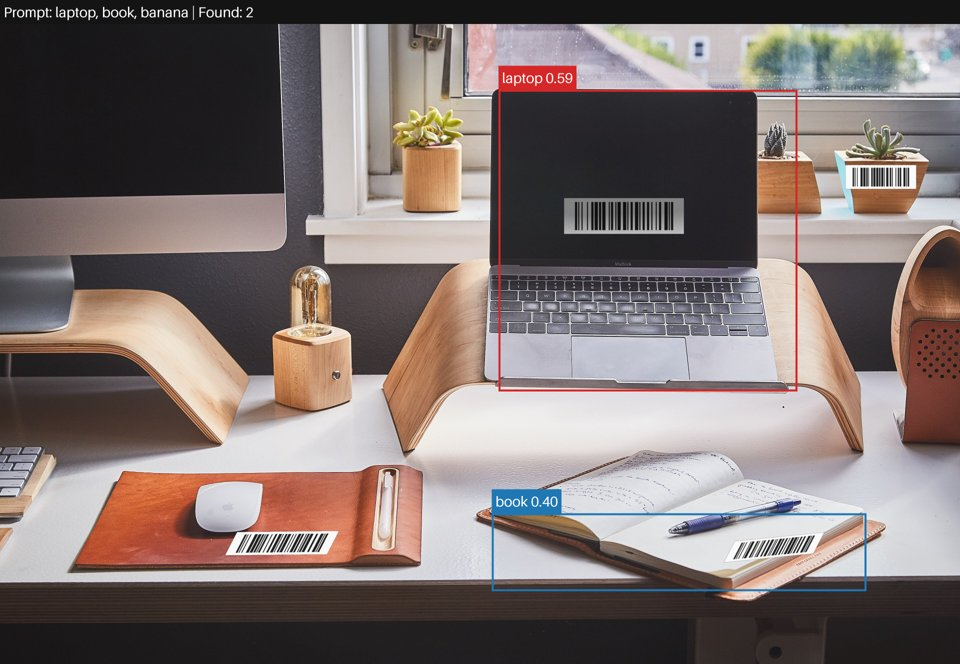

In [3]:
query = ["laptop", "book", "banana"]
scene = scenes["input_6.jpg"]
objects = scene.detect(query)
print(f"Prompt {query}: {len(objects)} objects")
print_objects(objects)
output = scene.draw_detections(query)
save_image(output, OUTPUT / "objects_list_input_6.jpg")
show(output)

Prompt "all": 12 objects
  paper        score 0.46  box (0, 1076, 1537, 1744)
  pen          score 0.46  box (2007, 1562, 3064, 1673)
  object       score 0.02  box (458, 1300, 708, 1411)
  object       score 0.03  box (218, 1240, 525, 1357)
  object       score 0.02  box (1052, 1177, 1372, 1387)
  object       score 0.02  box (515, 1198, 764, 1324)
  object       score 0.04  box (972, 1212, 1080, 1309)
  object       score 0.02  box (632, 1159, 1075, 1412)
  mug          score 0.60  box (412, 468, 1156, 1212)
  ruler        score 0.41  box (1769, 1662, 3832, 1829)
  object       score 0.08  box (221, 1159, 1383, 1418)
  paper        score 0.34  box (411, 1484, 3235, 2191)


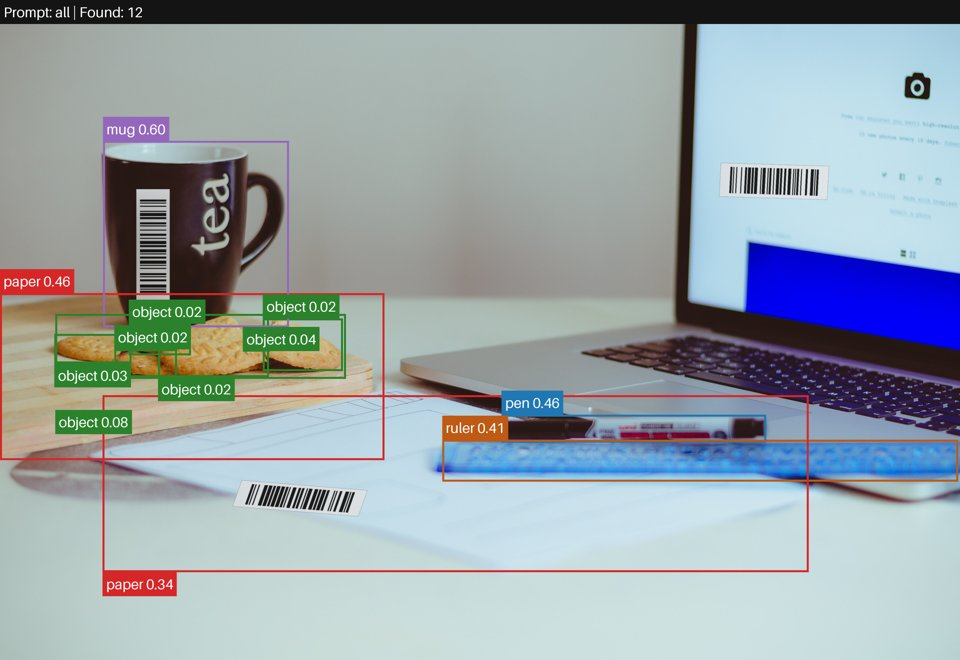

In [4]:
scene = scenes["input_5.jpg"]
objects = scene.detect("all")
print(f'Prompt "all": {len(objects)} objects')
print_objects(objects)
output = scene.draw_detections("all")
save_image(output, OUTPUT / "objects_all_input_5.jpg")
show(output)

## 3. Barcodes and their surface normals

Only the codes on the requested objects come back, each with its value, its outline and the 3D arrow of
its surface normal. The normal is a unit vector in camera coordinates: x to the right, y down and z away
from the camera, so a label facing the camera has a negative z. A robot can use it to approach the label
straight on.

Prompt ['laptop', 'mug']: 2 barcodes
  MG466        center (612, 887)  normal (+0.10, +0.21, -0.97)
  LT902        center (3096, 630)  normal (-0.63, +0.08, -0.77)


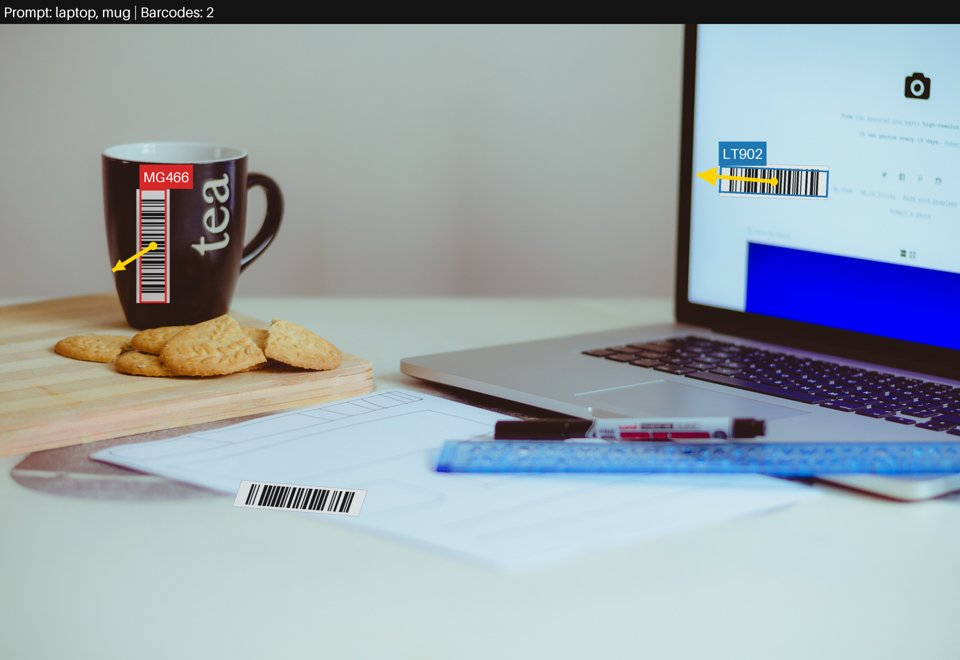

In [5]:
query = ["laptop", "mug"]
scene = scenes["input_5.jpg"]
barcodes = scene.read_barcodes(query)
print(f"Prompt {query}: {len(barcodes)} barcodes")
print_barcodes(barcodes)
output = scene.draw_barcodes(query)
save_image(output, OUTPUT / "barcodes_list_input_5.jpg")
show(output)

Prompt "all": 4 barcodes
  LT63         center (3251, 912)  normal (-0.02, -0.17, -0.99)
  PH118        center (448, 1678)  normal (+0.12, -0.24, -0.96)
  NB775        center (2463, 1439)  normal (+0.06, -0.25, -0.97)
  X001NB42K7   center (1560, 1934)  normal (+0.05, -0.24, -0.97)


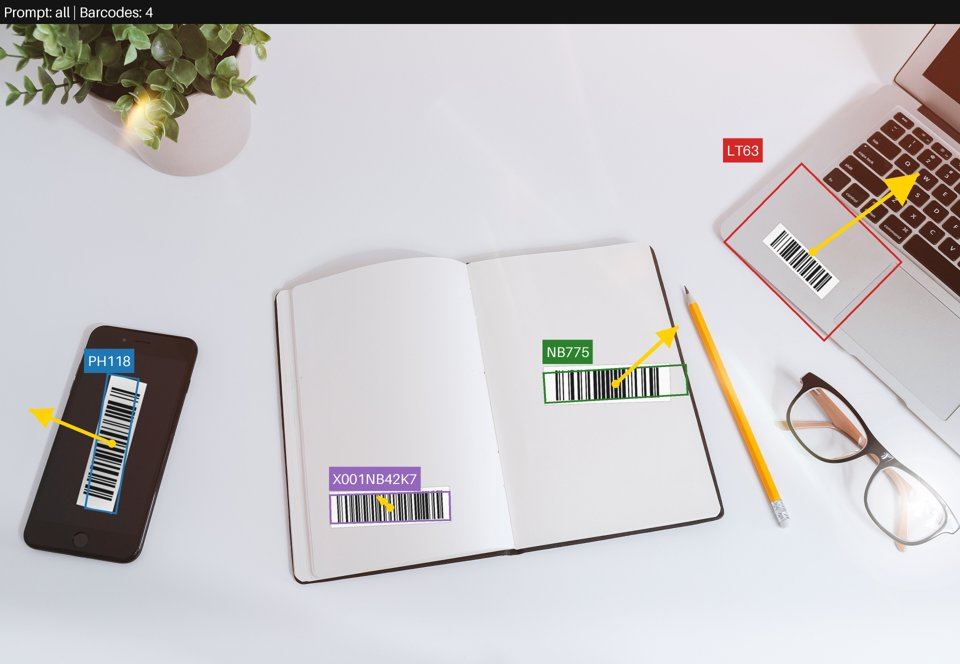

In [6]:
scene = scenes["input_2.jpg"]
barcodes = scene.read_barcodes("all")
print(f'Prompt "all": {len(barcodes)} barcodes')
print_barcodes(barcodes)
output = scene.draw_barcodes("all")
save_image(output, OUTPUT / "barcodes_all_input_2.jpg")
show(output)

## 4. From an object to its barcodes, and back

A barcode belongs to the smallest detected box that holds its centre; its value is never compared with
the object's name. An exact barcode value is matched first, then a name. This photo holds eight mugs,
three of them labelled: asking for `mug` gives the values on the mugs the detector found, and a value
gives its mug. The last two queries show the answer when there is nothing to give.

In [7]:
scene = scenes["input_1.jpg"]
for query in ("mug", "MG380", "laptop", "ZZ999"):
    relation = scene.relate(query)
    print(f"relate({query!r}) -> {relation.answers}" + (f"  ({relation.reason})" if relation.reason else ""))

relate('mug') -> ('MG380', 'MG57')
relate('MG380') -> ('mug',)


relate('laptop') -> ()  (no detected object or read barcode matches the query)


relate('ZZ999') -> ()  (no detected object or read barcode matches the query)


## 5. All the photos

Objects and barcodes with `"all"` on every photo. The images and a JSON report of each photo are saved
in `examples/output`; below, a small contact sheet of the barcode outputs. The seconds are the new work
on each photo: those already used above reuse what they computed.

input_1.jpg: 11 objects, barcodes [MG57, MG214, MG380, CL903], 6.1 s of new work


input_2.jpg: 6 objects, barcodes [LT63, PH118, NB775, X001NB42K7], 12.8 s of new work


input_3.jpg: 6 objects, barcodes [BK831, TB246, LT509, NB320], 153.4 s of new work


input_4.jpg: 5 objects, barcodes [MN725], 32.2 s of new work


input_5.jpg: 12 objects, barcodes [MG466, PP137, LT902], 0.0 s of new work


input_6.jpg: 6 objects, barcodes [PD650, PL71, NB204], 140.6 s of new work


input_7.jpg: 3 objects, barcodes [MN513, BX847], 137.5 s of new work


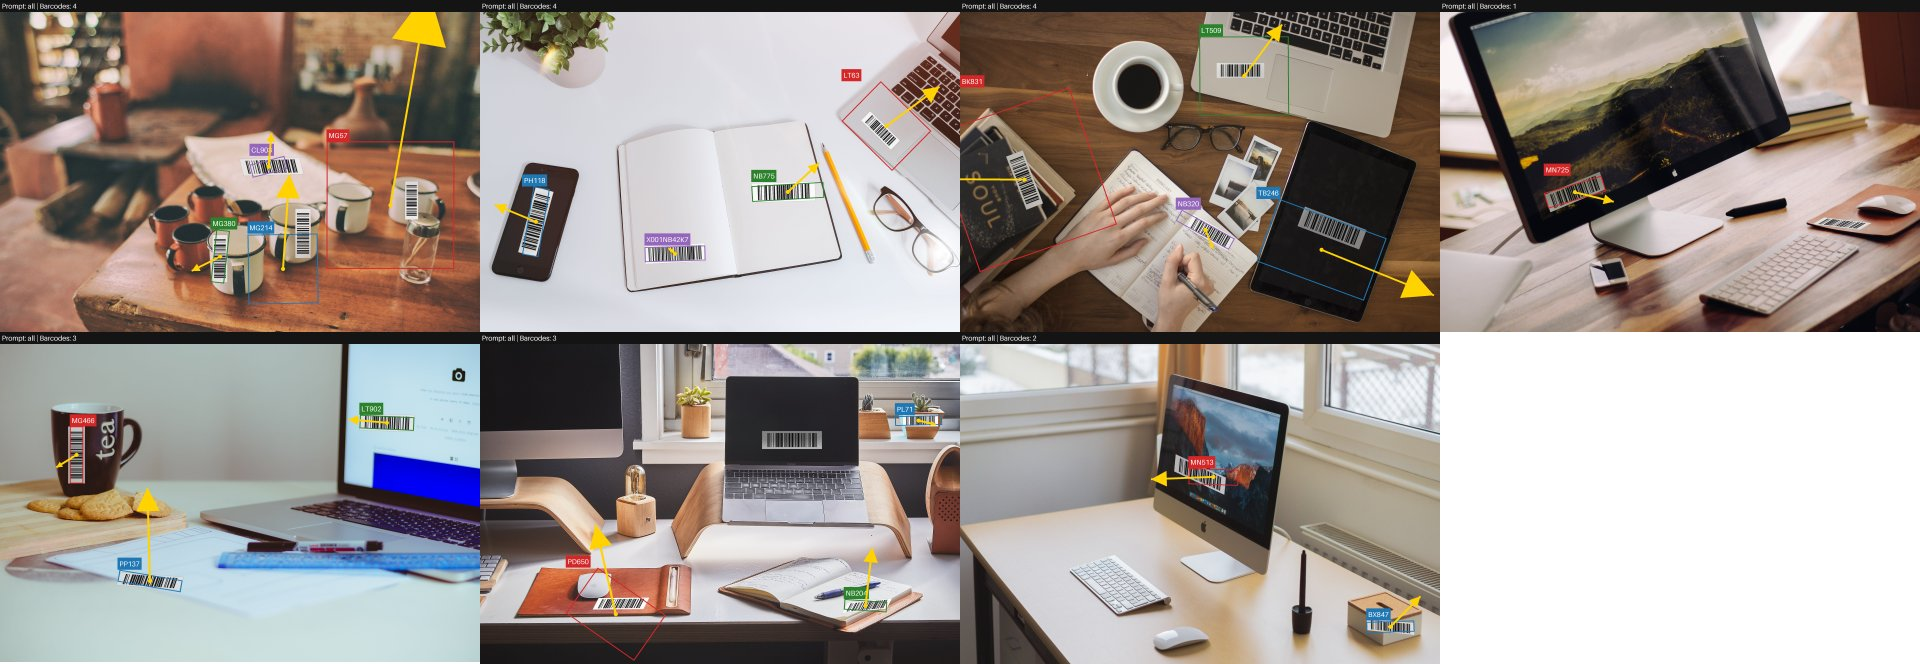

In [8]:
sheet = []
for name, scene in scenes.items():
    start = perf_counter()
    objects, barcodes = scene.detect("all"), scene.read_barcodes("all")
    seconds = perf_counter() - start
    stem = Path(name).stem
    save_image(scene.draw_detections("all"), OUTPUT / f"objects_all_{stem}.jpg")
    drawn = save_image(scene.draw_barcodes("all"), OUTPUT / f"barcodes_all_{stem}.jpg")
    save_report(scene.report("all"), OUTPUT / f"report_{stem}.json")
    values = ", ".join(code.value for code in barcodes)
    print(f"{name}: {len(objects)} objects, barcodes [{values}], {seconds:.1f} s of new work")
    sheet.append(Image.open(drawn).reduce(8))

columns, (width, height) = 4, sheet[0].size
contact = Image.new("RGB", (columns * width, -(-len(sheet) // columns) * height), "white")
for index, image in enumerate(sheet):
    contact.paste(image, ((index % columns) * width, (index // columns) * height))
show(contact, width=contact.width)

## 6. Export to JSON

Each report holds the objects, and for each barcode its value, corners, unit normal and the object it is
printed on, with the seconds spent per stage. Another system can use it directly, for instance a robot
that has to pick up the mug.

In [9]:
report = scenes["input_5.jpg"].report(["laptop", "mug"])
print(json.dumps(report, indent=2))

{
  "image": "input_5.jpg",
  "size": [
    3840,
    2543
  ],
  "query": [
    "laptop",
    "mug"
  ],
  "objects": [
    {
      "name": "laptop",
      "score": 0.6598,
      "box": [
        1669.53,
        11.89,
        3840.0,
        1829.48
      ]
    },
    {
      "name": "mug",
      "score": 0.4966,
      "box": [
        412.41,
        467.65,
        1155.53,
        1212.11
      ]
    }
  ],
  "barcodes": [
    {
      "value": "MG466",
      "corners": [
        [
          666.27,
          1116.05
        ],
        [
          558.27,
          1115.94
        ],
        [
          558.73,
          658.95
        ],
        [
          666.73,
          659.05
        ]
      ],
      "normal": [
        0.1035,
        0.2108,
        -0.972
      ],
      "object": "mug"
    },
    {
      "value": "LT902",
      "corners": [
        [
          2875.33,
          674.19
        ],
        [
          2880.31,
          566.3
        ],
        [
         

## 7. Timings

Each stage runs only when a task needs it, and once per photo. These are the seconds of one photo, then
the same round of queries repeated.

In [10]:
scene = scenes["input_2.jpg"]
for stage, seconds in scene.timings.items():
    print(f"  {stage:<26} {seconds:6.2f} s")
start = perf_counter()
scene.detect("all"), scene.read_barcodes("all"), scene.relate("laptop")
seconds = perf_counter() - start
record("same queries again", seconds)
print(f"Same queries again: {1000 * seconds:.0f} ms")

  load image                   0.15 s
  read barcodes               79.23 s
  estimate normals (MoGe)      5.75 s
  encode image (OWLv2)        12.78 s
  find all objects             0.04 s
Same queries again: 102 ms


## 8. Known failures

Measured with the benchmarks on these seven photos; the README gives the details.

| Where | What happens |
|---|---|
| Objects, `"all"` | 33 of 49 objects get a box. Pens, mice, plants seen from above and the monitor of photo 4 (larger than 35 % of the photo) are missed; names outside the vocabulary come out as the closest word: the tablet and a mouse pad as `laptop`, glasses as `object` |
| Objects, a list | With the default threshold of 0.34, 34 of 49 objects are found and 24 boxes are wrong; no absent name gets a box |
| Barcodes | 21 of 23 labels read, no false value. Missed: PD19 on the mouse pad of photo 4, seen at a grazing angle, and LT388 on the black screen of photo 6 |
| Barcode outlines | 9 of 21 outlines spread over the background around the label, which spoils their normal and can move their centre out of their object |
| Linking | With the detector's boxes 11 of 21 codes land on the right box: MG214 in photo 1 is read, but its mug is not detected |
| Speed | Reading takes 20 to 149 s per photo on these desks, against about 7 s on a clean table: keyboards, handwriting and wood grain give many striped areas to check |

Photo 6 below shows three of them: the screen label that is not read, the mouse pad label whose outline
is larger than the label, and the plants without a box.

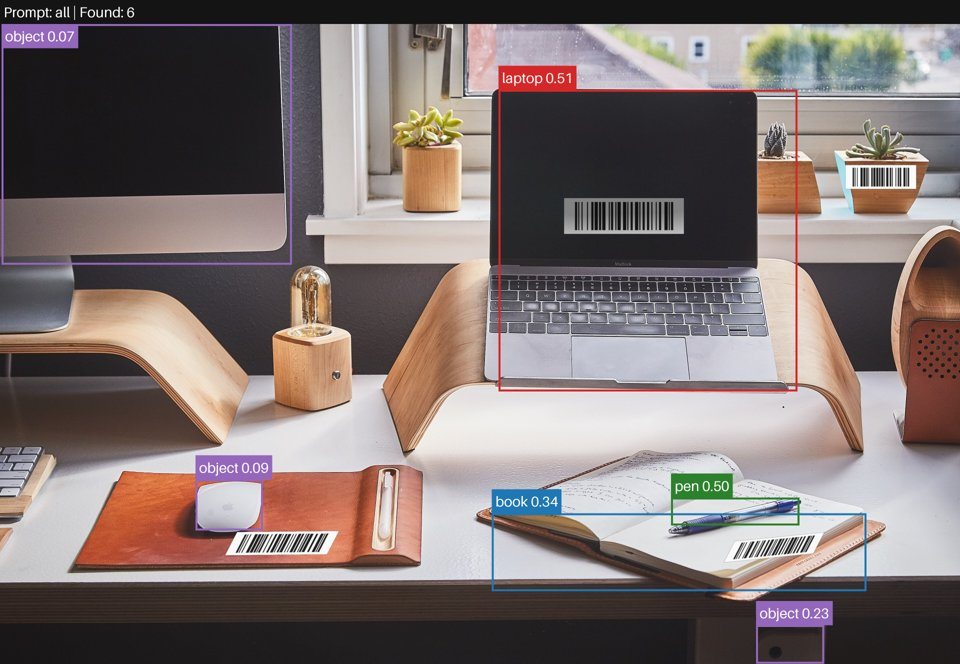

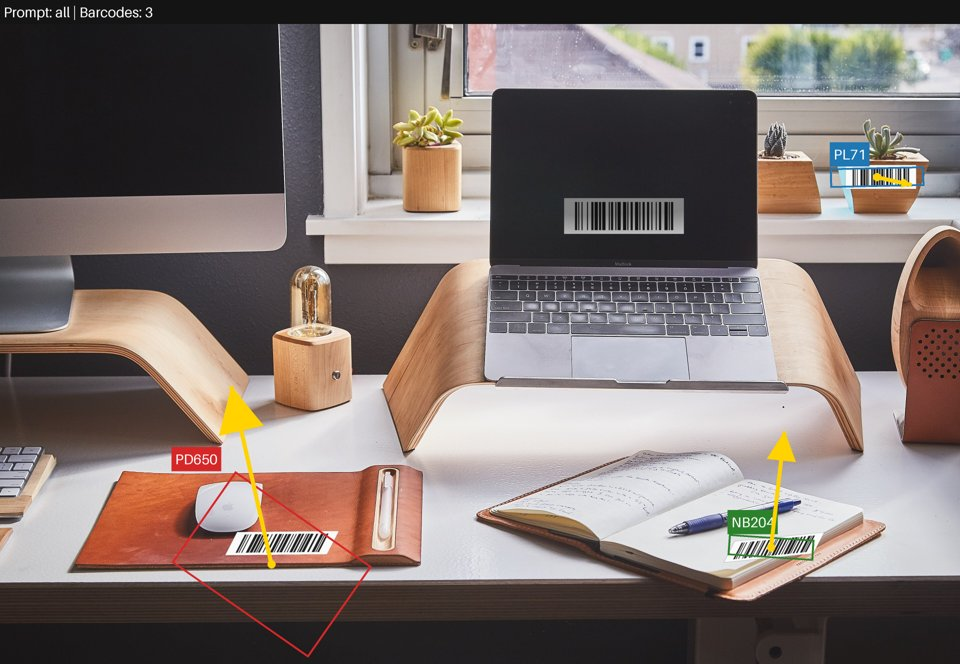

In [11]:
scene = scenes["input_6.jpg"]
show(scene.draw_detections("all"))
show(scene.draw_barcodes("all"))

## 9. Execution time report

Every run of this notebook rewrites `docs/execution-time-report.md` and `.json`: the date, the total
time, and the mean seconds of each stage next to the figure the README gives for it.

In [12]:
# One total per photo: every stage this notebook made it run, each once
for scene in scenes.values():
    record("all stages of one photo", sum(scene.timings.values()))
report = write_report()
print(report.read_text(encoding="utf-8") if report else "The report could not be written")

# Execution time report

Rewritten by every run of the program (`shelfvision.timing.write_report`); do not edit by hand.

| Field | Value |
|---|---|
| Date | 2026-11-18T21:57:58+00:00 |
| Total time | 956.1 s, since `shelfvision.timing` was imported |
| OS | Windows-11-10.0.26300-SP0 |
| CPU | AMD Ryzen 5 7520U with Radeon Graphics, 8 logical cores, 8 torch threads |
| RAM | 15.3 GiB |
| GPU | none seen by torch |

## Stages

Time is the mean of the runs, one run per photo for the model stages. Difference is against the
README's figure, measured under the conditions listed below the table.

| Stage | Time (s) | Runs | README claim | Difference (%) |
|---|---:|---:|---:|---:|
| load image | 0.138 | 7 | - | - |
| encode image (OWLv2) | 14.791 | 7 | 13.4 s | +10.4 |
| find requested objects | 0.516 | 6 | - | - |
| find all objects | 0.189 | 7 | - | - |
| read barcodes | 109.950 | 7 | 104.0 s | +5.7 |
| estimate normals (MoGe) | 6.854 | 7 | 6.0 s | +14.2 |
| same queries again | 0.102 | 1